# Laboratory Work No. 3: Numerical Modeling of Elastic Beam and Plate Bending

This notebook provides an interactive workflow for simulating fourth-order boundary value problems using the modular package in `labs/lab3`:

1. **1D Continuous Beam:** Fourth-order ordinary differential equation $EI y^{(4)}(x) = w(x)$ solved via the five-diagonal sweep method with clamped, guided, and free boundary conditions plus internal point supports.
2. **2D Rectangular Plate:** Biharmonic partial differential equation $D \Delta^2 U(x, y) = w(x, y)$ discretized on a 13-point finite-difference stencil and solved via successive over-relaxation.
3. **Axisymmetric Polar Annular Plate:** Radial biharmonic equation in polar coordinates on $r \in [r_a, r_b]$ solved via the five-diagonal sweep method and benchmarked against closed-form homogeneous solutions.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from labs.lab3.config import Config
from labs.lab3.dimensions.beam_1d import (
    get_beam_scenarios,
    run_all_beam_scenarios,
    solve_beam,
)
from labs.lab3.dimensions.plate_2d import (
    get_plate_scenarios,
    run_all_plate_scenarios,
    solve_plate,
)
from labs.lab3.dimensions.polar_disk import (
    PolarBoundary,
    PolarScenario,
    run_all_polar_scenarios,
    solve_polar,
)
from labs.lab3.visualization import (
    plot_beam_errors,
    plot_beam_results,
    plot_plate_results,
    plot_polar_results,
)

# Ensure local modules resolve whether Jupyter starts at repo root or labs/lab3
lab_dir = Path.cwd()
if (
    not (lab_dir / "config.py").exists()
    and (lab_dir / "labs" / "lab3" / "config.py").exists()
):
    lab_dir = lab_dir / "labs" / "lab3"
if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))

%matplotlib inline
cfg = Config()
print("Loaded default configuration:", cfg)

Loaded default configuration: Config(task='all', beam=BeamConfig(L=1.0, EI=1.0, q=1.0, N=1000, supports=[(0.3333333333333333, 0.0), (0.6666666666666666, 0.0)]), plate=PlateConfig(L_x=1.0, L_y=1.0, N_x=46, N_y=46, D=1.0, q=-100.0, epsilon=1e-09, max_iter=50000, omega=1.85), polar=PolarConfig(r_a=1.0, r_b=2.0, N_r=200, D=1.0, q=0.0))


## 1. One-Dimensional Continuous Beam

We evaluate all six benchmark scenarios from Section 2.3 covering clamped endpoints, sliding guided supports, cantilever free ends, and multi-span internal supports.

Task 2.3: Clamped ends, sinusoidal load                    | y in [-2.0617e+00, +1.2085e+00] | max |err| = 5.919e-03
Task 2.4: Clamped ends, point displacement at x=1/3        | y in [-1.1027e+00, +0.0000e+00] | max |err| = N/A
Task 2.5: Clamped left, guided right end                   | y in [-2.7639e-01, +0.0000e+00] | max |err| = 1.385e-03
Task 2.6: Three-span beam, clamped ends                    | y in [-2.9849e-01, +1.5087e-02] | max |err| = N/A
Task 2.7: Three-span beam, guided ends                     | y in [-2.0492e-01, +5.0496e-04] | max |err| = N/A
Task 2.8: Cantilever beam, clamped left and free right     | y in [-1.9402e-02, +0.0000e+00] | max |err| = 4.264e-05


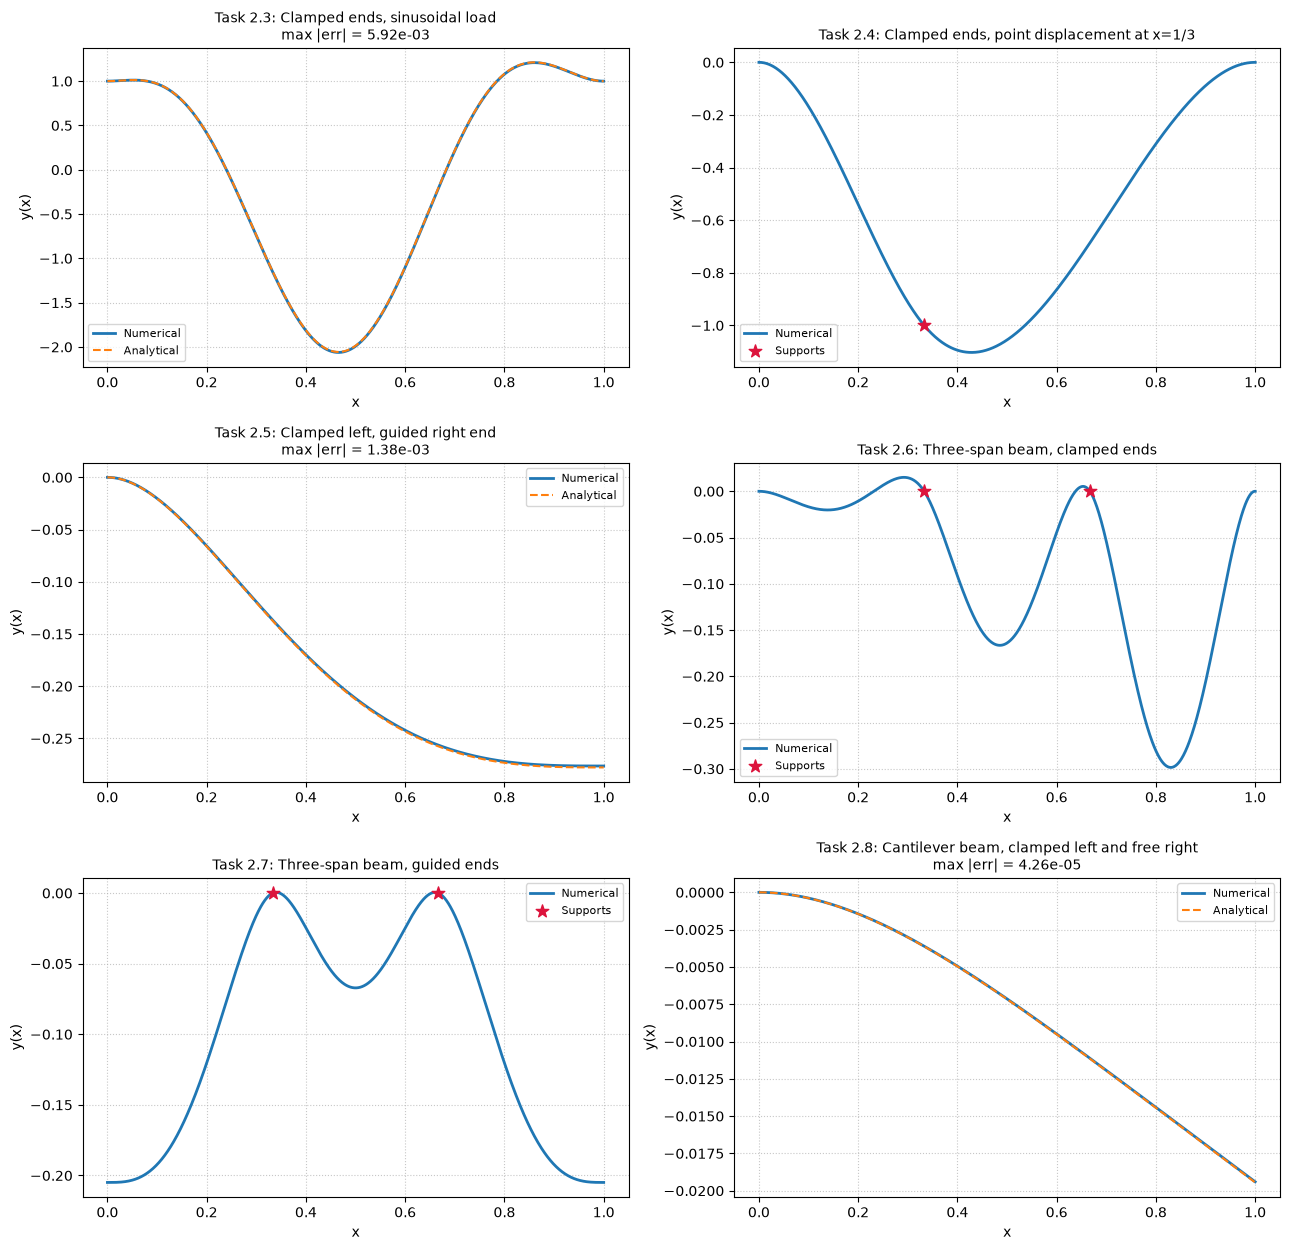

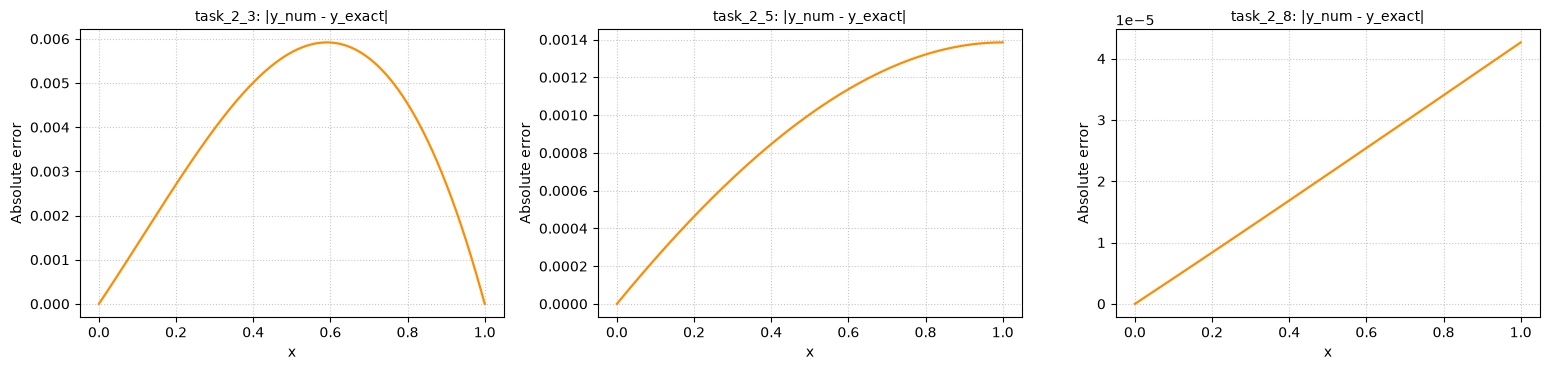

In [2]:
beam_results = run_all_beam_scenarios(cfg.beam)

for res in beam_results:
    err_str = f"{res.max_abs_error:.3e}" if res.max_abs_error is not None else "N/A"
    print(
        f"{res.title:<58} | "
        f"y in [{res.y_num.min():+.4e}, {res.y_num.max():+.4e}] | "
        f"max |err| = {err_str}"
    )

fig_beam = plot_beam_results(beam_results, show=False)
fig_beam_err = plot_beam_errors(beam_results, show=False)

### 1.1 Grid Convergence Study for the 1D Scheme

Because the five-point central difference stencil approximates $y^{(4)}(x)$ with truncation error $O(h^2)$, halving the spatial step $h$ should reduce the maximum absolute error by roughly a factor of $4$, corresponding to an empirical convergence order $p \approx 2$.

     N |       Step h |    Max |err| | Empirical Order
-------------------------------------------------------
    25 |   3.5714e-02 |   4.7771e-02 |               -
    50 |   1.8868e-02 |   2.5702e-02 |           0.894
   100 |   9.7087e-03 |   1.3352e-02 |           0.945
   200 |   4.9261e-03 |   6.8079e-03 |           0.972
   400 |   2.4814e-03 |   3.4378e-03 |           0.986
   800 |   1.2453e-03 |   1.7275e-03 |           0.993


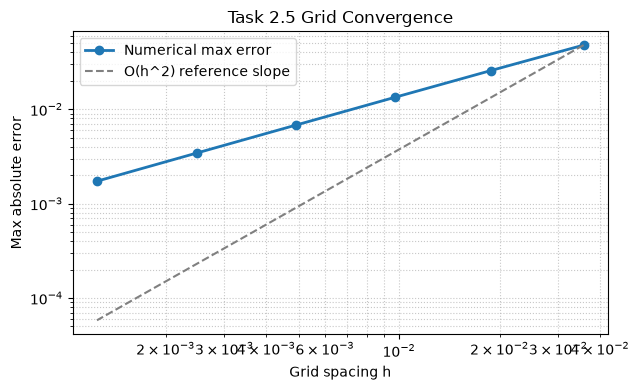

In [3]:
scenario_2_5 = get_beam_scenarios()["task_2_5"]
node_counts = [25, 50, 100, 200, 400, 800]
steps = []
errors = []

for n_nodes in node_counts:
    sub_cfg = replace(cfg.beam, N=n_nodes)
    res = solve_beam(sub_cfg, scenario_2_5)
    assert res.max_abs_error is not None
    steps.append(sub_cfg.L / (n_nodes + 3))
    errors.append(res.max_abs_error)

print(f"{'N':>6} | {'Step h':>12} | {'Max |err|':>12} | {'Empirical Order':>15}")
print("-" * 55)
for idx, (n_nodes, h_val, err_val) in enumerate(
    zip(node_counts, steps, errors, strict=True)
):
    order_str = f"{np.log2(errors[idx - 1] / err_val):.3f}" if idx > 0 else "-"
    print(f"{n_nodes:>6} | {h_val:>12.4e} | {err_val:>12.4e} | {order_str:>15}")

fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.loglog(steps, errors, "o-", linewidth=2.0, label="Numerical max error")
ref_line = errors[0] * (np.array(steps) / steps[0]) ** 2
ax.loglog(steps, ref_line, "--", color="gray", label="O(h^2) reference slope")
ax.set_title("Task 2.5 Grid Convergence")
ax.set_xlabel("Grid spacing h")
ax.set_ylabel("Max absolute error")
ax.grid(True, which="both", linestyle=":", alpha=0.7)
ax.legend()
fig.tight_layout()

## 2. Two-Dimensional Rectangular Plate

Next, we solve the biharmonic equation on a $46 \times 46$ grid using successive over-relaxation with $\omega = 1.85$ for three clamped plate configurations: a two-span plate, a plate with a central point support, and an unloaded plate deformed by four prescribed point displacements.

Task 3.1: Two-span clamped plate, uniform load       | converged in  4000 iters | res=9.97e-10 | U in [-1.6223e-02, +0.0000e+00]
Task 3.2: Clamped plate with central point support   | converged in  5678 iters | res=9.99e-10 | U in [-2.2916e-02, +0.0000e+00]
Task 3.3: Clamped plate with four point displacements | converged in  4309 iters | res=1.00e-09 | U in [-1.0619e+00, +2.0000e+00]


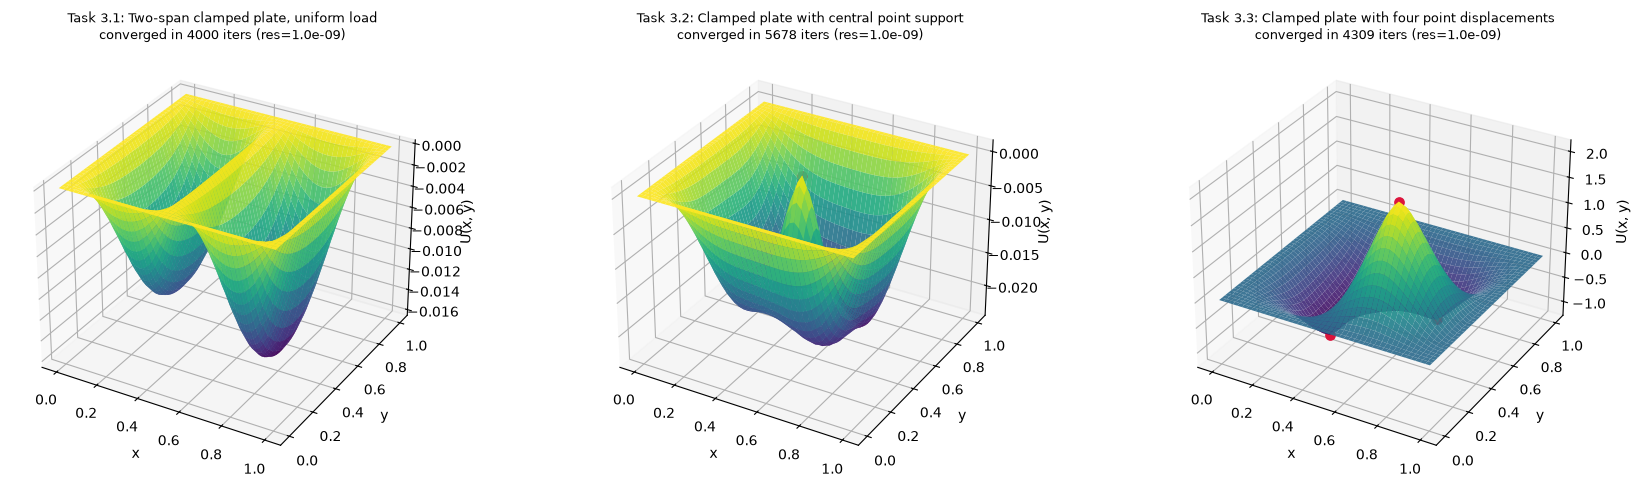

In [4]:
plate_results = run_all_plate_scenarios(cfg.plate)

for res in plate_results:
    status = "converged" if res.converged else "max_iter"
    print(
        f"{res.title:<52} | {status:<9} in {res.iterations:>5} iters | "
        f"res={res.residual:.2e} | U in [{res.u.min():+.4e}, {res.u.max():+.4e}]"
    )

fig_plate = plot_plate_results(plate_results, show=False)

### 2.1 Effect of Relaxation Factor $\omega$ on SOR Convergence

Selecting $\omega \in (1, 2)$ strongly affects convergence speed for the ill-conditioned fourth-order biharmonic operator. Below we compare iteration counts on a $26 \times 26$ grid across several values of $\omega$.

omega = 1.20 -> iterations = 2205, residual = 9.99e-08
omega = 1.50 -> iterations = 1239, residual = 9.96e-08
omega = 1.70 -> iterations = 675, residual = 9.90e-08
omega = 1.85 -> iterations = 609, residual = 9.79e-08
omega = 1.92 -> iterations = 1075, residual = 9.92e-08


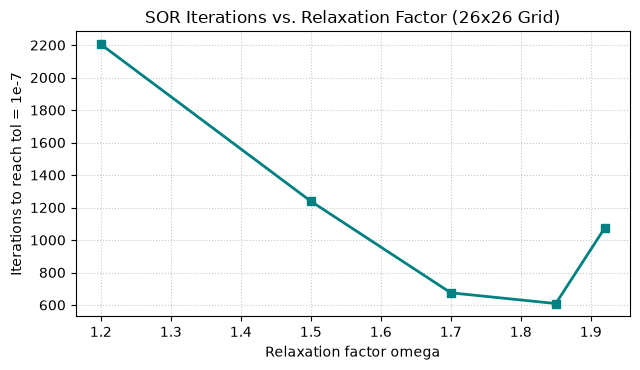

In [5]:
scenario_3_1 = get_plate_scenarios()["task_3_1"]
omegas = [1.2, 1.5, 1.7, 1.85, 1.92]
iter_counts = []

for w in omegas:
    fast_cfg = replace(cfg.plate, N_x=26, N_y=26, omega=w, epsilon=1e-7, max_iter=25000)
    res = solve_plate(fast_cfg, scenario_3_1)
    iter_counts.append(res.iterations)
    print(
        f"omega = {w:.2f} -> iterations = {res.iterations}, residual = {res.residual:.2e}"
    )

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(omegas, iter_counts, "s-", linewidth=2.0, color="teal")
ax.set_title("SOR Iterations vs. Relaxation Factor (26x26 Grid)")
ax.set_xlabel("Relaxation factor omega")
ax.set_ylabel("Iterations to reach tol = 1e-7")
ax.grid(True, linestyle=":", alpha=0.7)
fig.tight_layout()

## 3. Axisymmetric Polar Annular Plate

Finally, we model radial bending on the annulus $r \in [1, 2]$ for the three boundary combinations in Section 4.4 and compare each numerical profile with the exact analytical solution $\varphi(r) = C_1 + C_2 \ln r + C_3 r^2 + C_4 r^2 \ln r$.

Task 4.4: Clamped inner and outer edges                  | phi in [+0.0000e+00, +1.0000e+00] | max |err| = 1.758e-03
Task 4.5: Hinged inner edge, clamped outer edge          | phi in [+0.0000e+00, +1.0000e+00] | max |err| = 1.045e-03
Task 4.6: Guided inner edge, sloped clamped outer edge   | phi in [+6.3451e-01, +1.0000e+00] | max |err| = 5.745e-04


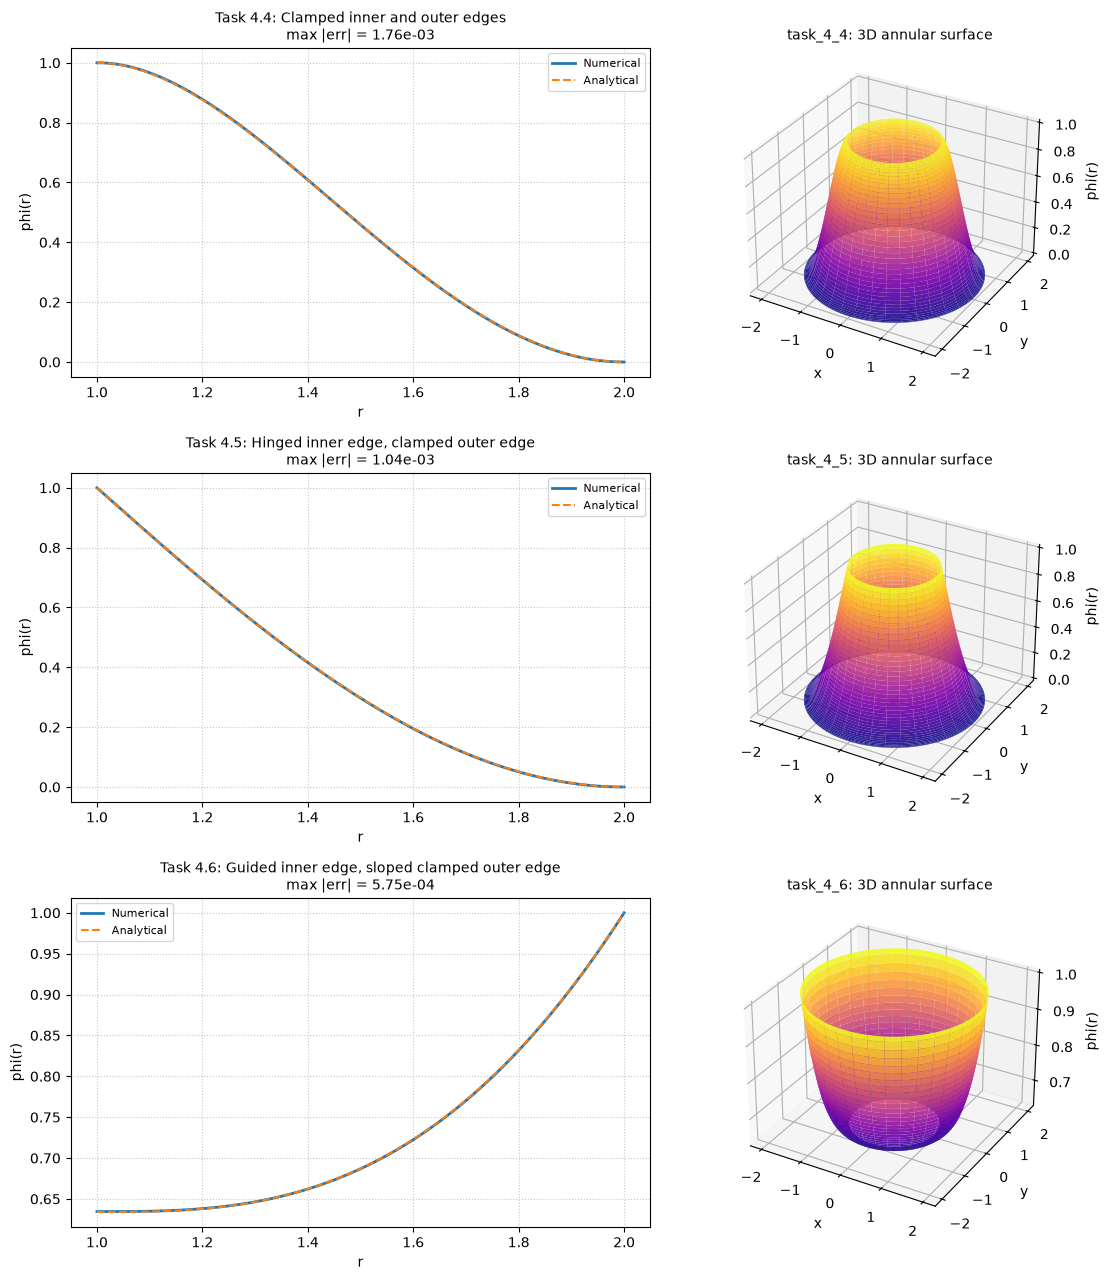

In [6]:
polar_results = run_all_polar_scenarios(cfg.polar)

for res in polar_results:
    err_str = f"{res.max_abs_error:.3e}" if res.max_abs_error is not None else "N/A"
    print(
        f"{res.title:<56} | "
        f"phi in [{res.phi_num.min():+.4e}, {res.phi_num.max():+.4e}] | "
        f"max |err| = {err_str}"
    )

fig_polar = plot_polar_results(polar_results, show=False)

### 3.1 Custom Experiment: Clamped Annulus Under Transverse Pressure

We can also supply a custom radial load function $f(r)$ to `PolarScenario` to inspect how uniform downward pressure deforms a clamped annular plate.

Max downward deflection: -1.284018e-01 at r = 1.483


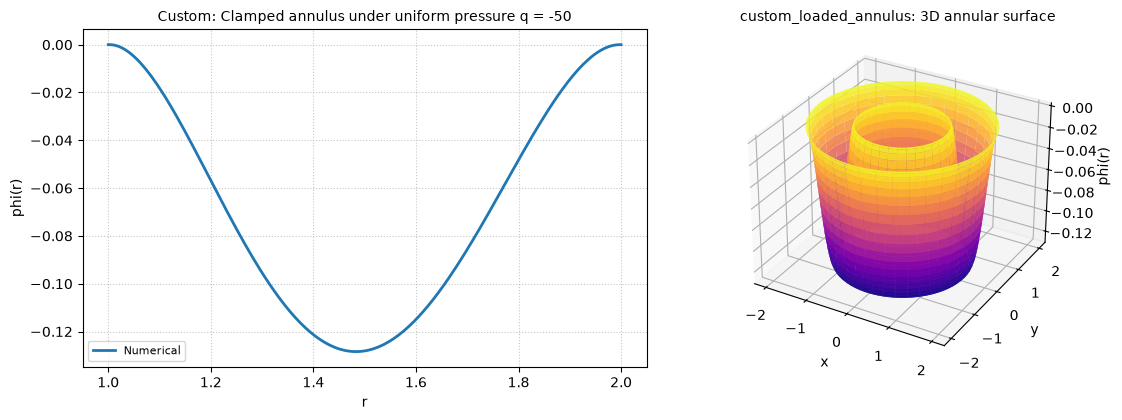

In [7]:
loaded_polar = PolarScenario(
    name="custom_loaded_annulus",
    title="Custom: Clamped annulus under uniform pressure q = -50",
    inner_bc=PolarBoundary("clamped", 0.0, 0.0),
    outer_bc=PolarBoundary("clamped", 0.0, 0.0),
    load_fn=lambda r: np.full_like(r, -50.0),
)

custom_res = solve_polar(cfg.polar, loaded_polar)
print(
    f"Max downward deflection: {custom_res.phi_num.min():.6e} at r = {custom_res.r[np.argmin(custom_res.phi_num)]:.3f}"
)
fig_custom_polar = plot_polar_results([custom_res], show=False)